# 05 — Forecasting acuan Way Urang

Penyaringan awal preprocessing memakai Ridge satu langkah t+30 menit, bukan keputusan final
untuk deep learning. P0 median, P1 ffill L4 dan P2 KNN k10; P3 ditunda.
Split 70/15/15 dipertahankan. Test tidak dimuat nilainya atau dievaluasi.
Seluruh algoritma dijalankan dari `scripts/forecast_ridge_way_urang.py`.

Histori train diimputasi dari prefix masa lalu, lalu fitur lag dibentuk.
Seluruh Ridge memakai timestamp pelatihan bersama dan fitur/model yang sama.


In [1]:
from pathlib import Path
import sys,os
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'outputs/.mplconfig'))
from IPython.display import display,Markdown,Image
import pandas as pd
from forecast_ridge_way_urang import Forecast
experiment=Forecast().prepare()
display(pd.DataFrame(experiment.pilot_seed))
display(pd.DataFrame(experiment.pilot_summary))
display(pd.DataFrame(experiment.distribution))
display(pd.DataFrame(experiment.monthly))
display(pd.DataFrame(experiment.locked_protocol))
print('Konfigurasi sudah dikunci sebelum fit:',experiment.config_hash)

Konfigurasi dikunci: f6b7aacb5e9a10f6532321a79acd780246439072871e74311a39b31803e511c1 ; belum ada Ridge fit.
Konfigurasi sudah dikunci sebelum fit: f6b7aacb5e9a10f6532321a79acd780246439072871e74311a39b31803e511c1


,Metode,Seed,Pola,Panjang slot,Panjang jam,Domain,Jumlah mask,Jumlah dinilai,Cakupan persen,MAE,RMSE,Bias,Fit detik,Scaler fit detik bersama,Transform detik,Prediksi negatif,Di luar rentang SO2 train
0,P0,11,titik,1,0.5,seluruh berhasil,452,452,100.000000,0.088274,0.110975,0.048407,0.000529,0.00000,0.000034,0,0
1,P0,11,titik,1,0.5,irisan semua metode,452,452,100.000000,0.088274,0.110975,0.048407,0.000529,0.00000,0.000034,0,0
2,P2_k10,11,titik,1,0.5,seluruh berhasil,452,452,100.000000,0.086778,0.109840,-0.000173,0.001626,0.02629,0.649149,0,0
3,P2_k10,11,titik,1,0.5,irisan semua metode,452,452,100.000000,0.086778,0.109840,-0.000173,0.001626,0.02629,0.649149,0,0
4,P0,11,blok,4,2.0,seluruh berhasil,120,120,100.000000,0.102833,0.126925,0.043667,0.000529,0.00000,0.000019,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,P2_k10,47,blok,184,92.0,irisan semua metode,368,2,0.543478,0.073786,0.076334,-0.019559,0.001626,0.02629,0.657727,0,0
68,P0,47,blok,981,490.5,seluruh berhasil,981,981,100.000000,0.094771,0.118618,0.054771,0.000529,0.00000,0.000004,0,0
69,P0,47,blok,981,490.5,irisan semua metode,981,1,0.101937,0.130000,0.130000,0.130000,0.000529,0.00000,0.000004,0,0
70,P2_k10,47,blok,981,490.5,seluruh berhasil,981,981,100.000000,0.089990,0.114554,0.005138,0.001626,0.02629,1.663198,0,0


,Metode,Pola,Panjang slot,Domain,Jumlah seed,MAE rata-rata,MAE SD antar-seed,MAE minimum,MAE maksimum,RMSE rata-rata,RMSE SD antar-seed,Bias rata-rata,Bias SD antar-seed,Cakupan persen rata-rata,Cakupan persen SD antar-seed,Cakupan persen minimum,Cakupan persen maksimum,Jumlah dinilai rata-rata,Jumlah dinilai SD antar-seed,Transform detik rata-rata,Transform detik SD antar-seed
0,P0,titik,1,seluruh berhasil,3,0.093053,0.009054,0.087389,0.103496,0.117482,0.014766,5.240413e-02,0.003547,100.000000,0.000000,100.000000,100.000000,452.000000,0.00000,0.000019,0.000013
1,P0,titik,1,irisan semua metode,3,0.093044,0.009063,0.087361,0.103496,0.117488,0.014761,5.251768e-02,0.003611,99.926254,0.127732,99.778761,100.000000,451.666667,0.57735,0.000019,0.000013
2,P2_k10,titik,1,seluruh berhasil,3,0.089505,0.008491,0.082713,0.099024,0.116131,0.014632,3.406836e-03,0.003165,99.926254,0.127732,99.778761,100.000000,451.666667,0.57735,0.738529,0.091840
3,P2_k10,titik,1,irisan semua metode,3,0.089505,0.008491,0.082713,0.099024,0.116131,0.014632,3.406836e-03,0.003165,99.926254,0.127732,99.778761,100.000000,451.666667,0.57735,0.738529,0.091840
4,P0,blok,4,seluruh berhasil,3,0.097639,0.004568,0.094250,0.102833,0.123392,0.004963,5.441667e-02,0.009411,100.000000,0.000000,100.000000,100.000000,120.000000,0.00000,0.000019,0.000003
5,P0,blok,4,irisan semua metode,3,0.092889,0.003151,0.089333,0.095333,0.117444,0.007769,4.577778e-02,0.012898,25.000000,0.000000,25.000000,25.000000,30.000000,0.00000,0.000019,0.000003
6,P2_k10,blok,4,seluruh berhasil,3,0.090790,0.004581,0.086025,0.095161,0.117924,0.004971,8.743880e-03,0.005801,100.000000,0.000000,100.000000,100.000000,120.000000,0.00000,0.177227,0.024847
7,P2_k10,blok,4,irisan semua metode,3,0.088469,0.002727,0.085460,0.090776,0.111005,0.005640,5.694057e-03,0.012078,25.000000,0.000000,25.000000,25.000000,30.000000,0.00000,0.177227,0.024847
8,P0,blok,71,seluruh berhasil,3,0.092660,0.004562,0.087394,0.095423,0.118431,0.008166,5.255086e-02,0.002206,100.000000,0.000000,100.000000,100.000000,426.000000,0.00000,0.000017,0.000008
9,P0,blok,71,irisan semua metode,3,0.078889,0.074802,0.030000,0.165000,0.095584,0.093607,7.777778e-03,0.020161,1.408451,0.000000,1.408451,1.408451,6.000000,0.00000,0.000017,0.000008


,Split,Bulan,Awal,Akhir,Slot grid,Pengamatan asli,Minimum,P1,P25,Median,P75,P99,Maksimum,Mean,SD,IQR
0,train,seluruh split,2025-01-01 00:00:00,2026-03-16 23:00:00,21119,19197,0.92,1.23,1.51,1.61,44.59,73.5112,80.71,13.975409,20.393319,43.08
1,validation,seluruh split,2026-03-16 23:30:00,2026-06-19 06:00:00,4526,4524,1.09,1.31,1.49,1.56,1.63,1.8200,2.06,1.560256,0.105310,0.14


,Split,Bulan,Awal,Akhir,Slot grid,Pengamatan asli,Minimum,P1,P25,Median,P75,P99,Maksimum,Mean,SD,IQR
0,train,2025-01,2025-01-01 00:00:00,2025-01-31 23:30:00,1488,385,0.92,1.1352,1.52,1.63,1.72,2.0548,2.15,1.615379,0.180945,0.20
1,train,2025-02,2025-02-01 00:00:00,2025-02-28 23:30:00,1344,730,1.24,1.3000,1.37,1.39,1.42,76.3439,79.57,3.698695,12.842677,0.05
2,train,2025-03,2025-03-01 00:00:00,2025-03-31 23:30:00,1488,1375,43.31,43.9218,45.04,45.54,46.14,78.0852,80.71,49.695382,10.565726,1.10
3,train,2025-04,2025-04-01 00:00:00,2025-04-30 23:30:00,1440,1434,43.53,44.0133,44.99,45.40,45.81,46.9234,47.43,45.403264,0.626197,0.82
4,train,2025-05,2025-05-01 00:00:00,2025-05-31 23:30:00,1488,1413,43.57,44.0412,44.99,45.39,45.83,46.8000,47.81,45.414275,0.611724,0.84
5,train,2025-06,2025-06-01 00:00:00,2025-06-30 23:30:00,1440,1440,1.07,1.2939,1.72,45.09,45.65,46.9283,47.78,33.306896,19.603313,43.93
6,train,2025-07,2025-07-01 00:00:00,2025-07-31 23:30:00,1488,1483,1.07,1.1582,1.48,1.56,1.64,1.9354,2.10,1.558786,0.139590,0.16
7,train,2025-08,2025-08-01 00:00:00,2025-08-31 23:30:00,1488,1486,1.04,1.3100,1.50,1.56,1.63,1.8300,2.05,1.563109,0.107819,0.13
8,train,2025-09,2025-09-01 00:00:00,2025-09-30 23:30:00,1440,1438,1.05,1.2100,1.49,1.56,1.63,1.8600,2.08,1.557990,0.117749,0.14
9,train,2025-10,2025-10-01 00:00:00,2025-10-31 23:30:00,1488,1488,1.04,1.1587,1.47,1.56,1.65,1.9400,2.14,1.559624,0.150609,0.18


,Keputusan,Nilai
0,created_utc,2026-11-05T14:02:04.887516+00:00
1,status,Dikunci sebelum forecasting; tanpa tuning hasi...
2,station,Way Urang pilot sementara
3,horizon_slots,1
4,horizon_minutes,30
5,so2_lags,"[0, 1, 2, 6, 12, 24, 48]"
6,covariates,"['PM10', 'PM2.5', 'CO', 'O3', 'NO2', 'Kec.Angi..."
7,covariate_lag_slots,1
8,pipelines,"['P0_median', 'P1_ffill_L4', 'P2_knn_k10']"
9,ffill_limit_slots,4


## Histori kausal sebelum lag

Kalibrasi awal 90 hari, pembaruan prefix setiap 30 hari di dalam train, lalu imputer
train dibekukan pada validasi. Histori lama tidak diperbaiki ulang.
Lag SO₂: 0,1,2,6,12,24,48. Kovariat pilot menggunakan satu slot keterlambatan.
Nilai SO₂ pada origin diasumsikan tersedia; latensi aktual masih perlu konfirmasi.
P1 memakai donor asli sebelumnya dan tidak diberi fallback median.


In [2]:
experiment.impute_history()
display(pd.DataFrame(experiment.prefix_logs))
display(pd.DataFrame(experiment.input_counts))
display(pd.DataFrame({'Fitur':experiment.feature_names}))

Histori kausal: 2025-04-01 00:00:00 - 2025-04-30 23:30:00
Histori kausal: 2025-05-01 00:00:00 - 2025-05-30 23:30:00
Histori kausal: 2025-05-31 00:00:00 - 2025-06-29 23:30:00
Histori kausal: 2025-06-30 00:00:00 - 2025-07-29 23:30:00
Histori kausal: 2025-07-30 00:00:00 - 2025-08-28 23:30:00
Histori kausal: 2025-08-29 00:00:00 - 2025-09-27 23:30:00
Histori kausal: 2025-09-28 00:00:00 - 2025-10-27 23:30:00
Histori kausal: 2025-10-28 00:00:00 - 2025-11-26 23:30:00
Histori kausal: 2025-11-27 00:00:00 - 2025-12-26 23:30:00
Histori kausal: 2025-12-27 00:00:00 - 2026-01-25 23:30:00
Histori kausal: 2026-01-26 00:00:00 - 2026-02-24 23:30:00
Histori kausal: 2026-02-25 00:00:00 - 2026-03-16 23:00:00
Histori kausal: 2026-03-16 23:30:00 - 2026-06-19 05:30:00


,Awal query,Akhir query,Fit sampai eksklusif,Timestamp donor maksimum,Jumlah baris prefix,Jumlah donor SO2 asli,Jumlah query,Query KNN ada sel kosong dan dukungan,Fit imputer dan scaler detik,Transform KNN detik,Periode,Median SO2 prefix
0,2025-04-01 00:00:00,2025-04-30 23:30:00,2025-04-01 00:00:00,2025-03-31 23:30:00,4320,2490,1440,1434,0.017250,0.185113,train prefix,44.665
1,2025-05-01 00:00:00,2025-05-30 23:30:00,2025-05-01 00:00:00,2025-04-30 23:30:00,5760,3924,1440,1365,0.003341,0.274122,train prefix,45.120
2,2025-05-31 00:00:00,2025-06-29 23:30:00,2025-05-31 00:00:00,2025-05-30 23:30:00,7200,5289,1440,1105,0.005779,0.293289,train prefix,45.210
3,2025-06-30 00:00:00,2025-07-29 23:30:00,2025-06-30 00:00:00,2025-06-29 23:30:00,8640,6729,1440,60,0.005298,0.025542,train prefix,45.200
4,2025-07-30 00:00:00,2025-08-28 23:30:00,2025-07-30 00:00:00,2025-07-29 23:30:00,10080,8164,1440,63,0.006935,0.026615,train prefix,44.960
5,2025-08-29 00:00:00,2025-09-27 23:30:00,2025-08-29 00:00:00,2025-08-28 23:30:00,11520,9602,1440,135,0.008579,0.070407,train prefix,44.590
6,2025-09-28 00:00:00,2025-10-27 23:30:00,2025-09-28 00:00:00,2025-09-27 23:30:00,12960,11040,1440,325,0.009839,0.180911,train prefix,1.770
7,2025-10-28 00:00:00,2025-11-26 23:30:00,2025-10-28 00:00:00,2025-10-27 23:30:00,14400,12480,1440,333,0.010536,0.230098,train prefix,1.690
8,2025-11-27 00:00:00,2025-12-26 23:30:00,2025-11-27 00:00:00,2025-11-26 23:30:00,15840,13920,1440,345,0.014383,0.247045,train prefix,1.660
9,2025-12-27 00:00:00,2026-01-25 23:30:00,2025-12-27 00:00:00,2025-12-26 23:30:00,17280,15360,1440,370,0.013829,0.357871,train prefix,1.640


,Pipeline,Jumlah fitur,Slot SO2 hilang asli setelah warmup,Slot SO2 terisi,Origin pasca warmup dengan seluruh fitur finite
0,P0_median,36,94,94,21276
1,P1_ffill_L4,36,94,23,17162
2,P2_knn_k10,36,94,17,21122


,Fitur
0,SO2_lag0
1,SO2_lag1
2,SO2_lag2
3,SO2_lag6
4,SO2_lag12
5,SO2_lag24
6,SO2_lag48
7,PM10_lag1
8,PM2.5_lag1
9,CO_lag1


## Ridge dan persistence pada target asli validasi

Ridge alpha=1, intercept=True, solver=svd untuk tiga pipeline; tanpa tuning.
Origin train yang targetnya masuk validasi dipurge. Timestamp train sama antar Ridge.
Persistence menggunakan SO₂ asli terakhir yang sudah tersedia pada origin.
Cakupan memakai seluruh target validasi asli teramati sebagai denominator.
Skor irisan dinilai pada timestamp yang berhasil untuk seluruh pipeline dan persistence.


,Pipeline,Origin train awal,Origin train akhir,Jumlah train kandidat target asli,Jumlah train fitur lengkap pipeline,Jumlah train bersama digunakan,Origin dipurge,Target origin dipurge,Target train maksimum
0,P0_median,2025-06-22 23:30:00,2026-03-16 22:30:00,16658,16658,12654,2026-03-16 23:00:00,2026-03-16 23:30:00,2026-03-16 23:00:00
1,P1_ffill_L4,2025-06-22 23:30:00,2026-03-16 22:30:00,16658,12664,12654,2026-03-16 23:00:00,2026-03-16 23:30:00,2026-03-16 23:00:00
2,P2_knn_k10,2025-06-22 23:30:00,2026-03-16 22:30:00,16658,16581,12654,2026-03-16 23:00:00,2026-03-16 23:30:00,2026-03-16 23:00:00


,Metode,Domain,Jumlah prediksi,Denominator target asli validasi,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif
0,P0_median,seluruh berhasil,4524,4524,100.000000,0.081652,0.105556,0.000543,0
1,P0_median,irisan semua metode,4487,4524,99.182140,0.081446,0.105314,0.000343,0
2,P1_ffill_L4,seluruh berhasil,4489,4524,99.226348,0.081451,0.105283,0.000209,0
3,P1_ffill_L4,irisan semua metode,4487,4524,99.182140,0.081452,0.105289,0.000230,0
4,P2_knn_k10,seluruh berhasil,4522,4524,99.955791,0.081665,0.105547,0.000501,0
5,P2_knn_k10,irisan semua metode,4487,4524,99.182140,0.081457,0.105296,0.000287,0
6,Persistence,seluruh berhasil,4524,4524,100.000000,0.115975,0.148921,0.000029,0
7,Persistence,irisan semua metode,4487,4524,99.182140,0.115830,0.148758,-0.000172,0


,Bulan target,Metode,Domain,Jumlah prediksi,Denominator target asli validasi,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif
0,2026-03,P0_median,seluruh berhasil,721,721,100.000000,0.074741,0.093972,0.000971,0
1,2026-03,P0_median,irisan semua metode,715,721,99.167822,0.074956,0.094128,0.000593,0
2,2026-04,P0_median,seluruh berhasil,1438,1438,100.000000,0.080086,0.103298,0.000005,0
3,2026-04,P0_median,irisan semua metode,1417,1438,98.539638,0.079504,0.102632,-0.000256,0
4,2026-05,P0_median,seluruh berhasil,1488,1488,100.000000,0.085981,0.113427,0.000427,0
5,2026-05,P0_median,irisan semua metode,1484,1488,99.731183,0.085911,0.113431,0.000127,0
6,2026-06,P0_median,seluruh berhasil,877,877,100.000000,0.082558,0.104357,0.001268,0
7,2026-06,P0_median,irisan semua metode,871,877,99.315849,0.082326,0.103946,0.001478,0
8,2026-03,P1_ffill_L4,seluruh berhasil,715,721,99.167822,0.074997,0.094151,0.000487,0
9,2026-03,P1_ffill_L4,irisan semua metode,715,721,99.167822,0.074997,0.094151,0.000487,0


,Strata,Metode,Domain,Jumlah prediksi,Denominator target asli validasi,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif
0,semua input asli lengkap,P0_median,irisan semua metode,3351,3351,100.000000,0.078742,0.100192,0.000035,0
1,ada SO2 historis missing,P0_median,irisan semua metode,12,14,85.714286,0.067730,0.096511,-0.037086,0
2,ada kovariat missing,P0_median,irisan semua metode,1125,1162,96.815835,0.089609,0.119318,0.001692,0
3,semua input asli lengkap,P1_ffill_L4,irisan semua metode,3351,3351,100.000000,0.078768,0.100211,-0.000079,0
4,ada SO2 historis missing,P1_ffill_L4,irisan semua metode,12,14,85.714286,0.065585,0.082216,-0.041350,0
5,ada kovariat missing,P1_ffill_L4,irisan semua metode,1125,1162,96.815835,0.089579,0.119297,0.001627,0
6,semua input asli lengkap,P2_knn_k10,irisan semua metode,3351,3351,100.000000,0.078769,0.100210,0.000009,0
7,ada SO2 historis missing,P2_knn_k10,irisan semua metode,12,14,85.714286,0.065748,0.082581,-0.041524,0
8,ada kovariat missing,P2_knn_k10,irisan semua metode,1125,1162,96.815835,0.089592,0.119322,0.001596,0
9,semua input asli lengkap,Persistence,irisan semua metode,3351,3351,100.000000,0.113306,0.144345,0.000451,0


,Pipeline,Scaler fitur fit detik,Ridge fit detik,Predict detik
0,P0_median,0.020551,0.038335,0.002311
1,P1_ffill_L4,0.016382,0.040450,0.002229
2,P2_knn_k10,0.009054,0.020818,0.001643


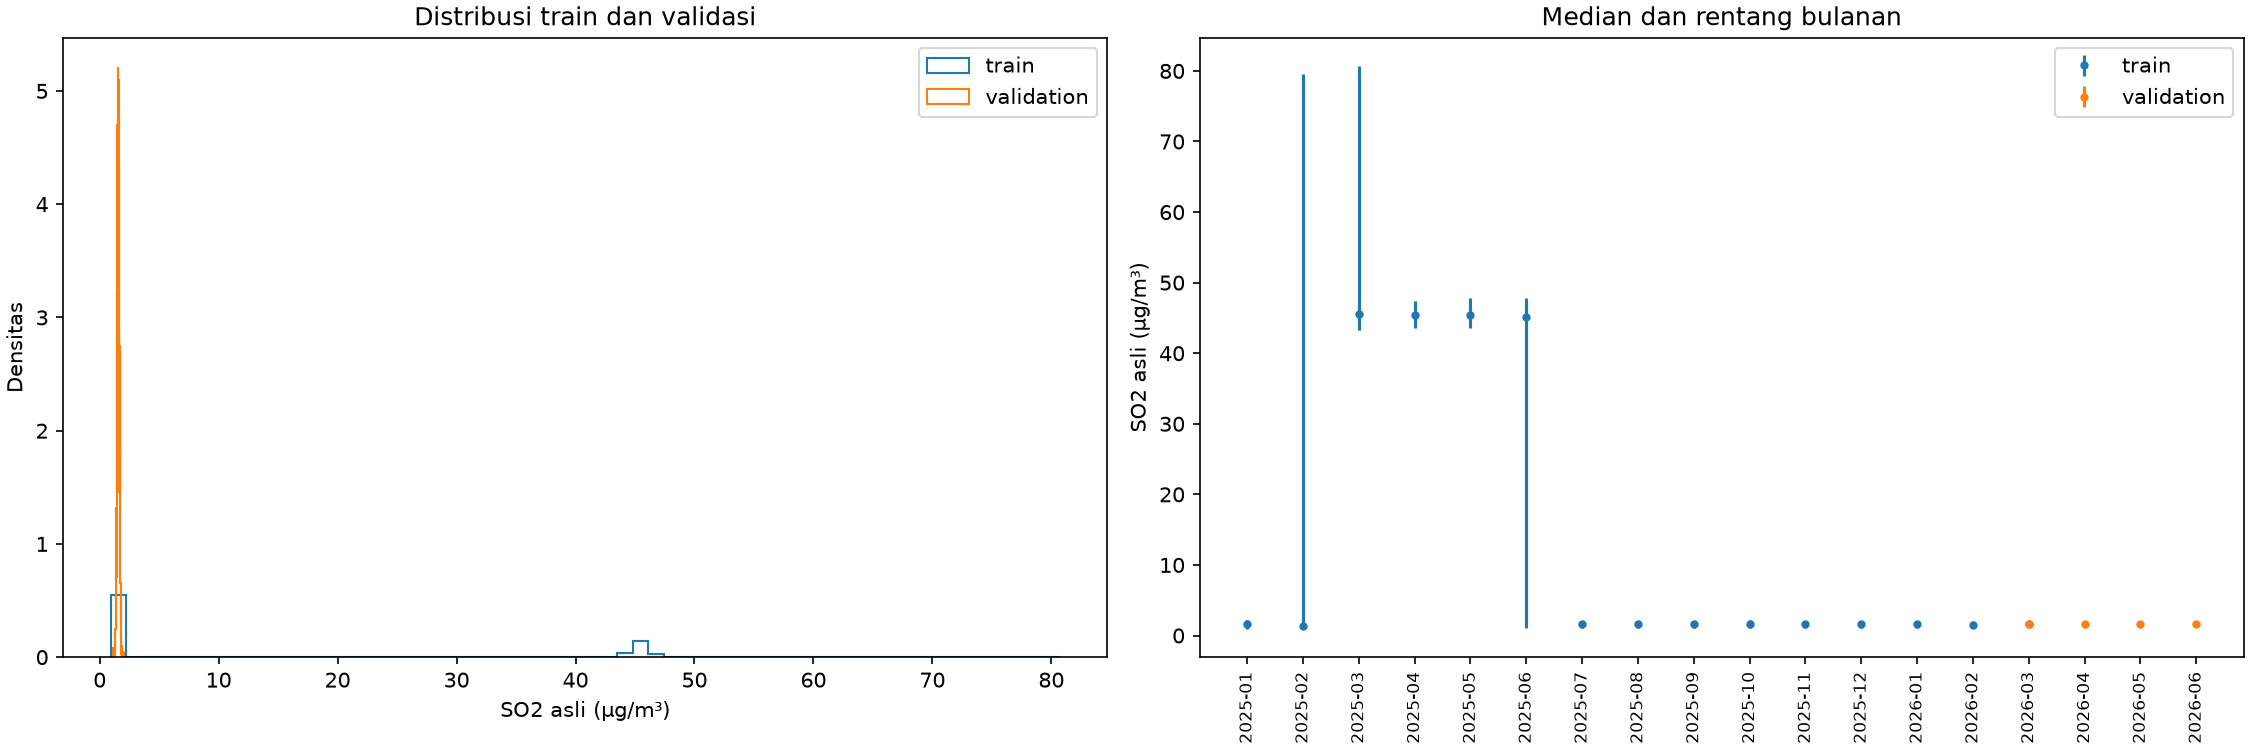

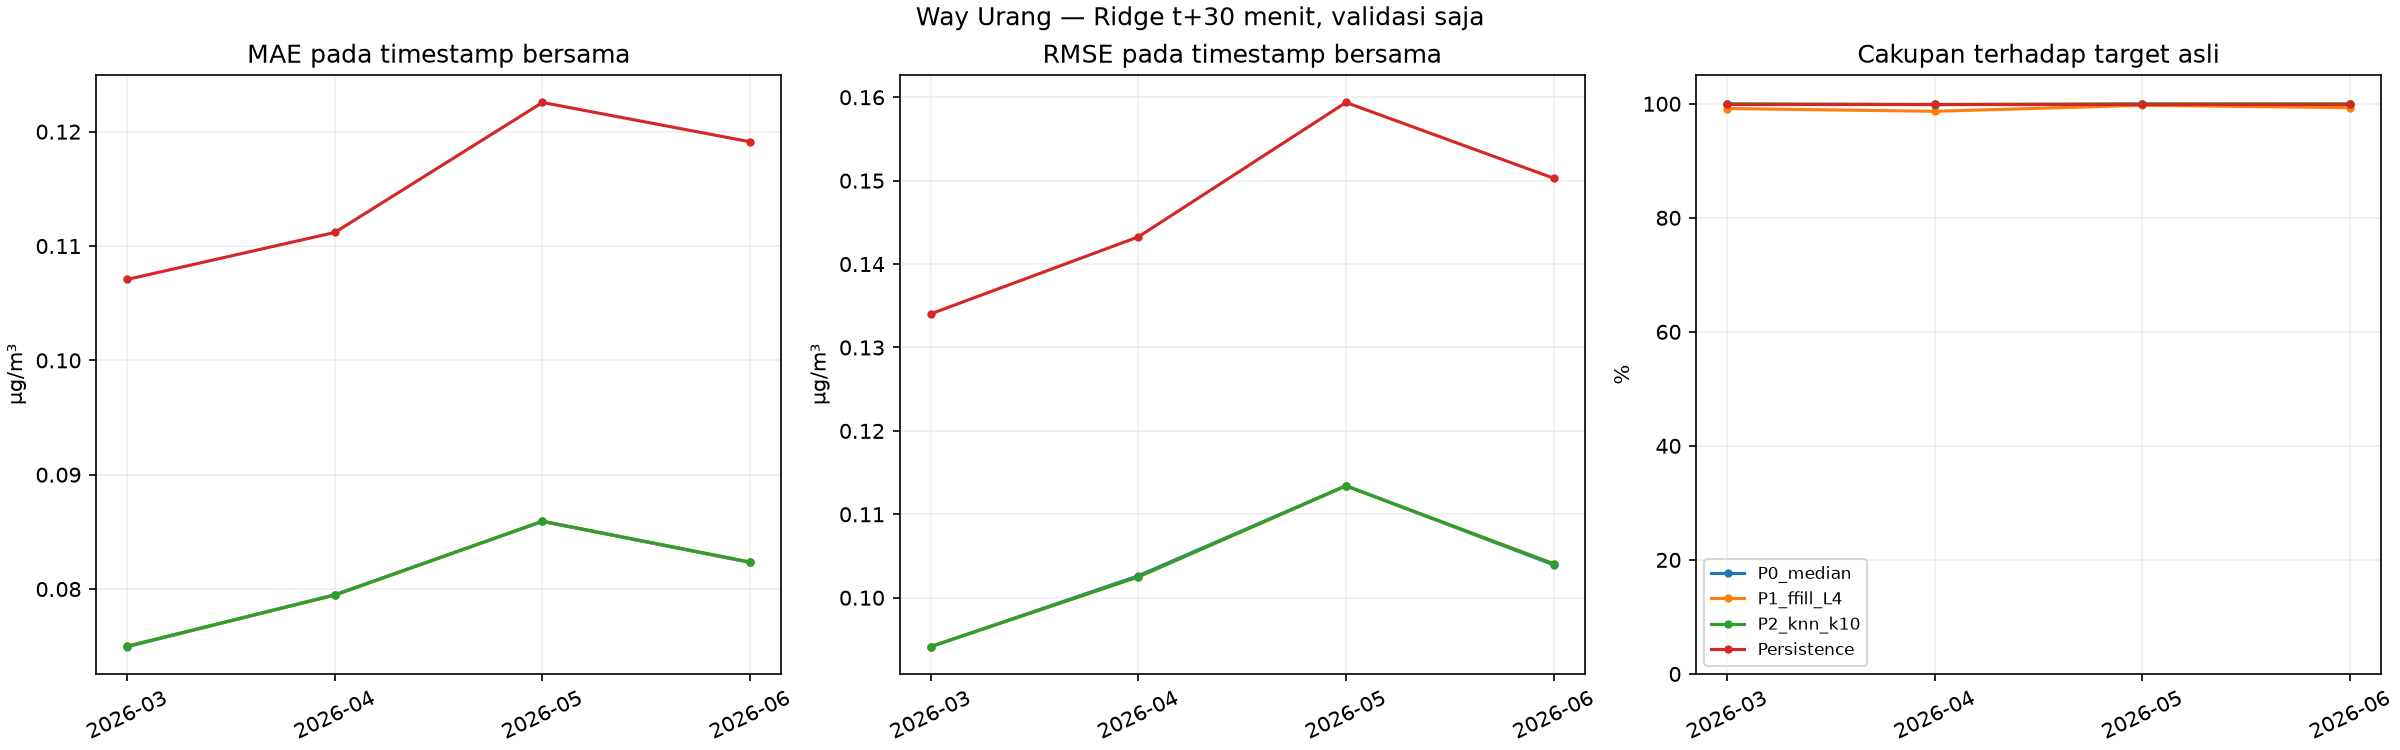

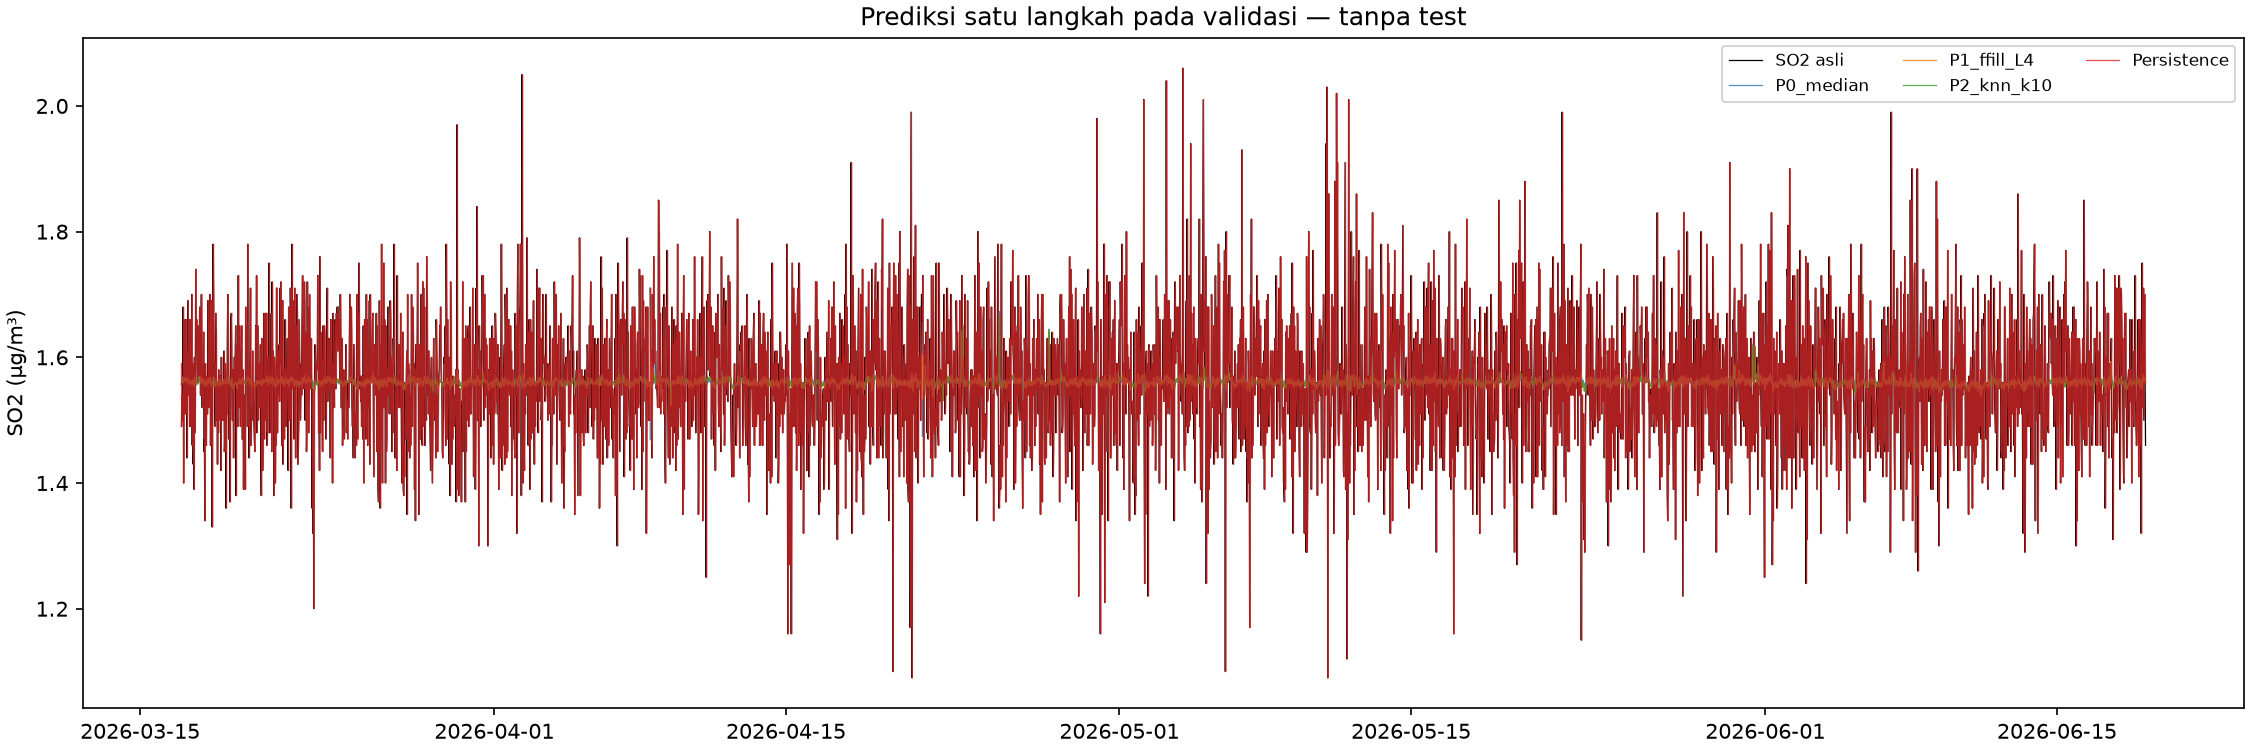

,File,SHA256 sebelum,SHA256 sesudah,Identik
0,data_raw\Telkom University Purwokerto - Intan ...,bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8...,bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8...,True
1,outputs\pilot_way_urang_tables.json,c9cc419e322c6bfdcfb6b357695ef8a92a526a03897e90...,c9cc419e322c6bfdcfb6b357695ef8a92a526a03897e90...,True
2,outputs\ringkasan_pilot_imputasi_way_urang.md,5709567715b6287ffd0cbcbe81b90b4167b96f7922cef9...,5709567715b6287ffd0cbcbe81b90b4167b96f7922cef9...,True
3,outputs\pilot_way_urang\config.json,a603c21ff24094a0340abe66c57b0be49fb33bd65a09af...,a603c21ff24094a0340abe66c57b0be49fb33bd65a09af...,True
4,outputs\pilot_way_urang\grid_dan_penanda_asli.csv,1d547e9b320bc547ef5a3ec8a1603df87cf4248f596288...,1d547e9b320bc547ef5a3ec8a1603df87cf4248f596288...,True
5,notebooks\04_pilot_imputasi_way_urang.ipynb,5d505fd390bf47153b587fde96c2b7016fde07cc51593a...,5d505fd390bf47153b587fde96c2b7016fde07cc51593a...,True
6,outputs\rancangan_eksperimen_preprocessing.md,d256294ac4568c82cbfeb9e06006b435dce293f52533bb...,d256294ac4568c82cbfeb9e06006b435dce293f52533bb...,True


In [3]:
experiment.fit_predict()
display(pd.DataFrame(experiment.train_detail))
display(pd.DataFrame(experiment.metrics))
display(pd.DataFrame(experiment.month_metrics))
display(pd.DataFrame(experiment.strata))
display(pd.DataFrame(experiment.timing))
for name in ['distribusi_train_validasi.png','performa_bulanan.png','prediksi_validasi.png']:
    display(Image(filename=str(ROOT/'outputs/figures/forecasting_way_urang'/name)))
display(pd.DataFrame(experiment.integrity))

## Ekspor dan kesimpulan terbatas

Prediksi, timestamp evaluasi, histori imputasi dan indikator disimpan terpisah dari sumber.
Perbandingan ini menyaring kandidat dengan Ridge; tidak menentukan preprocessing terbaik
untuk deep learning dan tidak menambahkan algoritma forecasting lain.


In [4]:
experiment.export_excel()
report=(ROOT/'outputs/ringkasan_forecasting_acuan_way_urang.md').read_text(encoding='utf-8')
display(Markdown(report.replace('(figures/', '(../outputs/figures/')))
print('Selesai. Tidak ada nilai atau skor test akhir dimuat/dievaluasi.')

{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Metode","Domain","Jumlah prediksi","Denominator target asli validasi","Cakupan persen","MAE"],["P0_median","seluruh berhasil",4524,4524,100,0.08165218159497452],["P0_median","irisan semua metode",4487,4524,99.18213969938108,0.08144613208967875],["P1_ffill_L4","seluruh berhasil",4489,4524,99.2263483642794,0.08145122935274807]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\forecasting_acuan_way_urang.xlsx.inspect.ndjson
Ekspor selesai: 19 sheet.

Selesai. Tidak ada nilai atau skor test akhir dimuat/dievaluasi.


# Forecasting acuan Way Urang — perbandingan preprocessing terkontrol

**Penyaringan awal satu langkah menggunakan Ridge, bukan keputusan akhir preprocessing deep learning.** Way Urang tetap pilot sementara. Tidak ada algoritma forecasting lain yang dilatih dan test akhir tidak dimuat nilainya atau dievaluasi. Split tetap seperti pilot tahap keempat.

## 1. Keterbatasan pilot yang ditinjau

Seluruh tabel/konfigurasi/penjelasan pilot dibaca kembali. Hasil rekontruksi sebelumnya menilai SO₂ yang sengaja disembunyikan, dengan kovariat lain tetap tersedia. Itu belum menjamin keuntungan pada forecasting target masa depan.

### MAE dan waktu setiap seed: median versus KNN k=10

| Metode | Seed | Pola | Panjang slot | Jumlah mask | Jumlah dinilai | MAE | Cakupan persen | Fit detik | Scaler fit detik bersama | Transform detik |
|---|---|---|---|---|---|---|---|---|---|---|
| P0 | 11 | titik | 1 | 452 | 452 | 0.088274 | 100.000 | 0.000529 | 0.000000 | 0.000034 |
| P2_k10 | 11 | titik | 1 | 452 | 452 | 0.086778 | 100.000 | 0.001626 | 0.026290 | 0.649149 |
| P0 | 11 | blok | 4 | 120 | 120 | 0.102833 | 100.000 | 0.000529 | 0.000000 | 0.000019 |
| P2_k10 | 11 | blok | 4 | 120 | 120 | 0.095161 | 100.000 | 0.001626 | 0.026290 | 0.192514 |
| P0 | 11 | blok | 71 | 426 | 426 | 0.087394 | 100.000 | 0.000529 | 0.000000 | 0.000018 |
| P2_k10 | 11 | blok | 71 | 426 | 426 | 0.081844 | 100.000 | 0.001626 | 0.026290 | 0.671012 |
| P0 | 11 | blok | 97 | 388 | 388 | 0.086701 | 100.000 | 0.000529 | 0.000000 | 0.000028 |
| P2_k10 | 11 | blok | 97 | 388 | 388 | 0.082781 | 100.000 | 0.001626 | 0.026290 | 0.808055 |
| P0 | 11 | blok | 184 | 368 | 368 | 0.086875 | 100.000 | 0.000529 | 0.000000 | 0.000017 |
| P2_k10 | 11 | blok | 184 | 368 | 368 | 0.085553 | 100.000 | 0.001626 | 0.026290 | 0.618987 |
| P0 | 11 | blok | 981 | 981 | 981 | 0.094159 | 100.000 | 0.000529 | 0.000000 | 0.000033 |
| P2_k10 | 11 | blok | 981 | 981 | 981 | 0.089821 | 100.000 | 0.001626 | 0.026290 | 1.586419 |
| P0 | 23 | titik | 1 | 452 | 452 | 0.103496 | 100.000 | 0.000529 | 0.000000 | 0.000008 |
| P2_k10 | 23 | titik | 1 | 452 | 452 | 0.099024 | 100.000 | 0.001626 | 0.026290 | 0.733791 |
| P0 | 23 | blok | 4 | 120 | 120 | 0.095833 | 100.000 | 0.000529 | 0.000000 | 0.000016 |
| P2_k10 | 23 | blok | 4 | 120 | 120 | 0.091183 | 100.000 | 0.001626 | 0.026290 | 0.190609 |
| P0 | 23 | blok | 71 | 426 | 426 | 0.095423 | 100.000 | 0.000529 | 0.000000 | 0.000008 |
| P2_k10 | 23 | blok | 71 | 426 | 426 | 0.088416 | 100.000 | 0.001626 | 0.026290 | 0.580199 |
| P0 | 23 | blok | 97 | 388 | 388 | 0.088582 | 100.000 | 0.000529 | 0.000000 | 0.000008 |
| P2_k10 | 23 | blok | 97 | 388 | 388 | 0.086065 | 100.000 | 0.001626 | 0.026290 | 0.570416 |
| P0 | 23 | blok | 184 | 368 | 368 | 0.095163 | 100.000 | 0.000529 | 0.000000 | 0.000019 |
| P2_k10 | 23 | blok | 184 | 368 | 368 | 0.090338 | 100.000 | 0.001626 | 0.026290 | 0.625810 |
| P0 | 23 | blok | 981 | 981 | 981 | 0.098287 | 100.000 | 0.000529 | 0.000000 | 0.000004 |
| P2_k10 | 23 | blok | 981 | 981 | 981 | 0.095426 | 100.000 | 0.001626 | 0.026290 | 1.775361 |
| P0 | 47 | titik | 1 | 452 | 452 | 0.087389 | 100.000 | 0.000529 | 0.000000 | 0.000016 |
| P2_k10 | 47 | titik | 1 | 452 | 451 | 0.082713 | 99.779 | 0.001626 | 0.026290 | 0.832646 |
| P0 | 47 | blok | 4 | 120 | 120 | 0.094250 | 100.000 | 0.000529 | 0.000000 | 0.000022 |
| P2_k10 | 47 | blok | 4 | 120 | 120 | 0.086025 | 100.000 | 0.001626 | 0.026290 | 0.148558 |
| P0 | 47 | blok | 71 | 426 | 426 | 0.095164 | 100.000 | 0.000529 | 0.000000 | 0.000025 |
| P2_k10 | 47 | blok | 71 | 426 | 426 | 0.091341 | 100.000 | 0.001626 | 0.026290 | 0.819044 |
| P0 | 47 | blok | 97 | 388 | 388 | 0.092242 | 100.000 | 0.000529 | 0.000000 | 0.000028 |
| P2_k10 | 47 | blok | 97 | 388 | 388 | 0.087691 | 100.000 | 0.001626 | 0.026290 | 0.632126 |
| P0 | 47 | blok | 184 | 368 | 368 | 0.093832 | 100.000 | 0.000529 | 0.000000 | 0.000018 |
| P2_k10 | 47 | blok | 184 | 368 | 368 | 0.088885 | 100.000 | 0.001626 | 0.026290 | 0.657727 |
| P0 | 47 | blok | 981 | 981 | 981 | 0.094771 | 100.000 | 0.000529 | 0.000000 | 0.000004 |
| P2_k10 | 47 | blok | 981 | 981 | 981 | 0.089990 | 100.000 | 0.001626 | 0.026290 | 1.663198 |

MAE di atas memakai seluruh titik yang berhasil tiap metode, sehingga N dapat berbeda. Perbandingan pada irisan pilot yang sama, seluruh hasil per-seed dan domain tersedia pada workbook. Fit pilot dilakukan satu kali lalu dipakai ulang; tidak boleh menjumlah ulang waktu fit setiap seed. Waktu scaler bersama dicatat terpisah.

| Metode | Pola | Panjang slot | MAE rata-rata | MAE SD antar-seed | MAE minimum | MAE maksimum | Transform detik rata-rata | Transform detik SD antar-seed |
|---|---|---|---|---|---|---|---|---|
| P0 | titik | 1 | 0.093053 | 0.009054 | 0.087389 | 0.103496 | 0.000019 | 0.000013 |
| P2_k10 | titik | 1 | 0.089505 | 0.008491 | 0.082713 | 0.099024 | 0.738529 | 0.091840 |
| P0 | blok | 4 | 0.097639 | 0.004568 | 0.094250 | 0.102833 | 0.000019 | 0.000003 |
| P2_k10 | blok | 4 | 0.090790 | 0.004581 | 0.086025 | 0.095161 | 0.177227 | 0.024847 |
| P0 | blok | 71 | 0.092660 | 0.004562 | 0.087394 | 0.095423 | 0.000017 | 0.000008 |
| P2_k10 | blok | 71 | 0.087201 | 0.004863 | 0.081844 | 0.091341 | 0.690085 | 0.120559 |
| P0 | blok | 97 | 0.089175 | 0.002818 | 0.086701 | 0.092242 | 0.000022 | 0.000011 |
| P2_k10 | blok | 97 | 0.085512 | 0.002501 | 0.082781 | 0.087691 | 0.670199 | 0.123309 |
| P0 | blok | 184 | 0.091957 | 0.004451 | 0.086875 | 0.095163 | 0.000018 | 0.000001 |
| P2_k10 | blok | 184 | 0.088259 | 0.002453 | 0.085553 | 0.090338 | 0.634175 | 0.020680 |
| P0 | blok | 981 | 0.095739 | 0.002228 | 0.094159 | 0.098287 | 0.000014 | 0.000016 |
| P2_k10 | blok | 981 | 0.091746 | 0.003189 | 0.089821 | 0.095426 | 1.674992 | 0.095022 |

SD adalah simpangan baku sampel tiga seed, bukan confidence interval independen karena lokasi mask dapat overlap. KNN memerlukan fit/scaling/donor dan transform lebih mahal daripada mengembalikan satu median; waktu komputer ini bukan jaminan latensi produksi atau perbandingan kompleksitas pada semua ukuran data.

### Distribusi SO₂ train dan validasi

| Split | Pengamatan asli | Minimum | P1 | P25 | Median | P75 | P99 | Maksimum | Mean | SD | IQR |
|---|---|---|---|---|---|---|---|---|---|---|---|
| train | 19197 | 0.92 | 1.23 | 1.51 | 1.61 | 44.59 | 73.51 | 80.71 | 13.98 | 20.39 | 43.08 |
| validation | 4524 | 1.09 | 1.31 | 1.49 | 1.56 | 1.63 | 1.82 | 2.06 | 1.56 | 0.11 | 0.14 |

| Split | Bulan | Slot grid | Pengamatan asli | Minimum | P25 | Median | P75 | Maksimum | SD | IQR |
|---|---|---|---|---|---|---|---|---|---|---|
| train | 2025-01 | 1488 | 385 | 0.92 | 1.52 | 1.63 | 1.72 | 2.15 | 0.18 | 0.20 |
| train | 2025-02 | 1344 | 730 | 1.24 | 1.37 | 1.39 | 1.42 | 79.57 | 12.84 | 0.05 |
| train | 2025-03 | 1488 | 1375 | 43.31 | 45.04 | 45.54 | 46.14 | 80.71 | 10.57 | 1.10 |
| train | 2025-04 | 1440 | 1434 | 43.53 | 44.99 | 45.40 | 45.81 | 47.43 | 0.63 | 0.82 |
| train | 2025-05 | 1488 | 1413 | 43.57 | 44.99 | 45.39 | 45.83 | 47.81 | 0.61 | 0.84 |
| train | 2025-06 | 1440 | 1440 | 1.07 | 1.72 | 45.09 | 45.65 | 47.78 | 19.60 | 43.93 |
| train | 2025-07 | 1488 | 1483 | 1.07 | 1.48 | 1.56 | 1.64 | 2.10 | 0.14 | 0.16 |
| train | 2025-08 | 1488 | 1486 | 1.04 | 1.50 | 1.56 | 1.63 | 2.05 | 0.11 | 0.13 |
| train | 2025-09 | 1440 | 1438 | 1.05 | 1.49 | 1.56 | 1.63 | 2.08 | 0.12 | 0.14 |
| train | 2025-10 | 1488 | 1488 | 1.04 | 1.47 | 1.56 | 1.65 | 2.14 | 0.15 | 0.18 |
| train | 2025-11 | 1440 | 1440 | 1.12 | 1.49 | 1.56 | 1.64 | 2.07 | 0.13 | 0.15 |
| train | 2025-12 | 1488 | 1488 | 1.08 | 1.49 | 1.57 | 1.65 | 2.03 | 0.14 | 0.16 |
| train | 2026-01 | 1488 | 1488 | 1.12 | 1.50 | 1.57 | 1.63 | 2.04 | 0.12 | 0.13 |
| train | 2026-02 | 1344 | 1342 | 1.08 | 1.49 | 1.55 | 1.62 | 2.02 | 0.12 | 0.13 |
| train | 2026-03 | 767 | 767 | 1.16 | 1.49 | 1.56 | 1.63 | 1.97 | 0.12 | 0.14 |
| validation | 2026-03 | 721 | 721 | 1.20 | 1.50 | 1.56 | 1.62 | 1.97 | 0.09 | 0.12 |
| validation | 2026-04 | 1440 | 1438 | 1.09 | 1.50 | 1.56 | 1.63 | 2.05 | 0.10 | 0.13 |
| validation | 2026-05 | 1488 | 1488 | 1.09 | 1.49 | 1.56 | 1.63 | 2.06 | 0.11 | 0.14 |
| validation | 2026-06 | 877 | 877 | 1.24 | 1.49 | 1.56 | 1.63 | 1.99 | 0.10 | 0.14 |

Secara deskriptif validasi lebih sempit: rentang 1.09–2.06 µg/m³ dan SD 0.10531, dibanding train 0.92–80.71 dan SD 20.3933. IQR validasi 0.14, train 43.08. Ini menunjukkan variasi pengamatan validasi lebih kecil pada periode tersebut, bukan bukti stasioneritas atau kesalahan sensor. Evaluasi ini belum mencakup kondisi SO₂ tinggi train. Batas split tidak diubah untuk memperbaiki skor.

![Distribusi SO2](../outputs/figures/forecasting_way_urang/distribusi_train_validasi.png)

## 2. Rancangan dikunci sebelum forecasting

Konfigurasi disimpan di `forecasting_way_urang/config_locked.json` sebelum pembentukan histori dan fit Ridge. SHA256 konfigurasi: `f6b7aacb5e9a10f6532321a79acd780246439072871e74311a39b31803e511c1`. Waktu pembuatan UTC: `2026-11-05T14:02:04.887516+00:00`. Hash diverifikasi kembali setelah eksperimen.
- Target: SO₂ asli pada t+30 menit (satu langkah), bukan horizon final penelitian.
- Pipeline: P0 median, P1 forward fill maksimum **4 slot/2 jam tanpa fallback median**, P2 KNN k=10 berbobot distance. P3 ditunda karena pilot belum konvergen dan menghasilkan nilai negatif.
- L=4 dipilih sebelum forecasting karena mencakup gap pendek train 1/4 slot; pilot L4 mengisi blok 4 slot seluruhnya, sedangkan L1 hanya 25%. Batas 71–981 slot akan meneruskan donor berhari-hari dan tidak dipilih untuk penyaringan awal. L4 bukan ambang sensor dan bukan hasil tuning forecasting.
- Model tunggal: `Ridge(alpha=1.0, fit_intercept=True, solver="svd")`, sama untuk tiga pipeline. Tidak ada pencarian alpha, seleksi fitur dari skor forecasting, atau model tambahan.
- SO₂ lag **0,1,2,6,12,24,48 slot**. Sebelas kovariat sama seperti pilot, semuanya lag satu slot: PM10, PM2.5, CO, O3, NO2, Kec.Angin, Kelembaban, Suhu, Tek.Udara, Sol.Rad, Curah Hujan. Arah angin linear dan waktu mentah tidak digunakan.
- Setiap Ridge mempunyai 18 fitur numerik dan 18 indikator missing asli. Algoritma/scaler/fitur dan timestamp train sama; parameter numerik scaler/koefisien boleh berbeda karena data hasil preprocessing berbeda.
- Baseline persistence: SO₂ **asli** terakhir yang tersedia pada atau sebelum origin, tanpa batas umur. Ia tidak memakai hasil imputasi pipeline mana pun.

| Split | Awal | Akhir | Jumlah slot | SO2 nonkosong asli |
|---|---|---|---|---|
| train | 2025-01-01 00:00:00 | 2026-03-16 23:00:00 | 21119 | 19197 |
| validation | 2026-03-16 23:30:00 | 2026-06-19 06:00:00 | 4526 | 4524 |
| test | 2026-06-19 06:30:00 | 2026-09-21 13:00:00 | 4526 | 4525 |

Inventaris test pada tabel disalin dari pilot; nilai test tidak dimuat. Test telah tercakup audit lama sehingga tidak disebut belum pernah dilihat.

## 3. Pembentukan histori dan fitur yang kausal

### Ketersediaan informasi

- SO₂ teramati pada u diasumsikan sudah tersedia saat origin u. Kovariat pada u−1 (30 menit sebelumnya) diasumsikan telah tersedia pada u, sama dengan pilot. Latensi aktual belum diketahui; bila lebih panjang, fitur dan evaluasi perlu digeser ulang. Tidak ada klaim bahwa timestamp sendiri membuktikan waktu kedatangan.
- Baris matriks rekonstruksi pada u adalah `[SO2(u), kovariat(u−1)]`. SO₂ hilang pada u diestimasi hanya dari kovariat asli yang sudah dilag dan donor train sebelumnya. Bila SO₂(u) teramati, nilainya dapat membantu KNN mengisi kovariat(u−1) yang kosong pada origin u. Ini bukan pemakaian target u+1.
- Nilai nonkosong asli tidak diganti. Nol, lonjakan, rentetan konstan dan ekstrem tetap dipertahankan. Baris off-grid Way Urang tetap ledger terpisah tahap 4 (2025-05-22 19:01, SO₂ kosong), tanpa pembulatan.

### Menghindari leakage di dalam train

Mengimputasi seluruh train dengan imputer yang di-fit pada seluruh train lalu memakai hasilnya untuk contoh historis awal akan memakai informasi yang belum tersedia pada origin itu. Karena itu digunakan prosedur prefix berikut:
1. **90 hari pertama** sebagai kalibrasi awal. Nilai kosong pada bagian ini tidak diisi menggunakan data sesudahnya. Ridge mulai menerima origin 48 slot setelah kalibrasi, agar seluruh lag SO₂ berasal dari periode histori yang telah diproses.
2. Pada train setelah kalibrasi, median dan scaler/KNN di-fit hanya pada prefix **sebelum** awal blok 30 hari. Parameter dibekukan untuk blok berikutnya. Pembaruan tetap berasal dari data train asli, bukan hasil imputasi.
3. Pada validasi, imputer dan scaler jarak KNN di-fit pada seluruh train lalu dibekukan. SO₂ validasi yang sudah benar-benar teramati boleh masuk sebagai histori setelah waktunya, tetapi tidak menjadi donor KNN atau estimator median.
4. P1 selalu memakai pengamatan asli sebelumnya per variabel dan berhenti setelah umur donor >4 slot. Hasil imputasi tidak mereset umur. Tidak ada fallback median.
5. P2 memakai donor train dengan SO₂ asli finite, scaler prefix yang mempertahankan NaN, guard minimal dua kovariat asli tersedia pada query, dan dukungan donor per kolom. Kolom tanpa dukungan tetap kosong; fallback bawaan tanpa overlap tidak diterima. Tidak ada clipping.
6. **Setelah histori selesai secara kausal**, fitur lag SO₂ dibentuk. Kovariat sudah dilag sebelum rekonstruksi dan tidak dilag lagi. Indikator missing berasal dari keadaan asli sebelum pengisian.
7. Ridge dilatih pada **irisan timestamp train dengan target asli dan fitur finite untuk ketiga pipeline**. Scaler fitur Ridge di-fit pada baris train bersama masing-masing pipeline. Ini mengontrol komposisi sampel pelatihan, tetapi mengurangi jumlah contoh dan membatasi generalisasi.
8. Origin train terakhir yang targetnya masuk validasi dikeluarkan dari train. Origin tersebut boleh menjadi origin prediksi pertama validasi. Target kosong tidak diisi untuk pelatihan maupun penilaian.

| Pipeline | Origin train awal | Origin train akhir | Jumlah train kandidat target asli | Jumlah train fitur lengkap pipeline | Jumlah train bersama digunakan | Origin dipurge | Target origin dipurge |
|---|---|---|---|---|---|---|---|
| P0_median | 2025-06-22 23:30:00 | 2026-03-16 22:30:00 | 16658 | 16658 | 12654 | 2026-03-16 23:00:00 | 2026-03-16 23:30:00 |
| P1_ffill_L4 | 2025-06-22 23:30:00 | 2026-03-16 22:30:00 | 16658 | 12664 | 12654 | 2026-03-16 23:00:00 | 2026-03-16 23:30:00 |
| P2_knn_k10 | 2025-06-22 23:30:00 | 2026-03-16 22:30:00 | 16658 | 16581 | 12654 | 2026-03-16 23:00:00 | 2026-03-16 23:30:00 |

### Distribusi target pada train yang benar-benar digunakan Ridge

| Bagian | Awal target | Akhir target | Jumlah target asli | Minimum | Median | Maksimum | Mean | SD |
|---|---|---|---|---|---|---|---|---|
| seluruh train bersama | 2025-06-23 00:00:00 | 2026-03-16 23:00:00 | 12654 | 1.04 | 1.56 | 2.14 | 1.56 | 0.13 |
| 2025-06 | 2025-06-23 00:00:00 | 2025-06-30 23:30:00 | 384 | 1.07 | 1.56 | 2.03 | 1.55 | 0.15 |
| 2025-07 | 2025-07-01 00:00:00 | 2025-07-31 23:30:00 | 1429 | 1.07 | 1.56 | 2.10 | 1.56 | 0.14 |
| 2025-08 | 2025-08-01 00:00:00 | 2025-08-31 23:30:00 | 1433 | 1.04 | 1.56 | 2.05 | 1.56 | 0.11 |
| 2025-09 | 2025-09-01 00:00:00 | 2025-09-30 23:30:00 | 1436 | 1.05 | 1.56 | 2.08 | 1.56 | 0.12 |
| 2025-10 | 2025-10-01 00:00:00 | 2025-10-31 23:30:00 | 1486 | 1.04 | 1.56 | 2.14 | 1.56 | 0.15 |
| 2025-11 | 2025-11-01 00:00:00 | 2025-11-30 23:30:00 | 1439 | 1.12 | 1.56 | 2.07 | 1.56 | 0.13 |
| 2025-12 | 2025-12-01 00:00:00 | 2025-12-31 23:30:00 | 1484 | 1.08 | 1.57 | 2.03 | 1.57 | 0.14 |
| 2026-01 | 2026-01-01 00:00:00 | 2026-01-31 23:30:00 | 1482 | 1.12 | 1.57 | 2.04 | 1.57 | 0.12 |
| 2026-02 | 2026-02-01 00:00:00 | 2026-02-28 23:30:00 | 1317 | 1.08 | 1.55 | 2.02 | 1.55 | 0.12 |
| 2026-03 | 2026-03-01 00:00:00 | 2026-03-16 23:00:00 | 764 | 1.16 | 1.56 | 1.97 | 1.56 | 0.12 |

Distribusi ini berbeda dari seluruh 70% train pada audit deskriptif. Kalibrasi awal dan persyaratan fitur lengkap untuk semua pipeline dapat mengeluarkan periode tertentu dari contoh Ridge, termasuk konsentrasi tinggi. Ini konsekuensi rancangan bersama yang telah ditetapkan, bukan perubahan batas split atau seleksi berdasarkan skor. Hasil Ridge harus ditafsirkan terhadap subset train aktual ini.

| Awal query | Akhir query | Timestamp donor maksimum | Jumlah baris prefix | Jumlah donor SO2 asli | Periode |
|---|---|---|---|---|---|
| 2025-04-01 00:00:00 | 2025-04-30 23:30:00 | 2025-03-31 23:30:00 | 4320 | 2490 | train prefix |
| 2025-05-01 00:00:00 | 2025-05-30 23:30:00 | 2025-04-30 23:30:00 | 5760 | 3924 | train prefix |
| 2025-05-31 00:00:00 | 2025-06-29 23:30:00 | 2025-05-30 23:30:00 | 7200 | 5289 | train prefix |
| 2025-06-30 00:00:00 | 2025-07-29 23:30:00 | 2025-06-29 23:30:00 | 8640 | 6729 | train prefix |
| 2025-07-30 00:00:00 | 2025-08-28 23:30:00 | 2025-07-29 23:30:00 | 10080 | 8164 | train prefix |
| 2025-08-29 00:00:00 | 2025-09-27 23:30:00 | 2025-08-28 23:30:00 | 11520 | 9602 | train prefix |
| 2025-09-28 00:00:00 | 2025-10-27 23:30:00 | 2025-09-27 23:30:00 | 12960 | 11040 | train prefix |
| 2025-10-28 00:00:00 | 2025-11-26 23:30:00 | 2025-10-27 23:30:00 | 14400 | 12480 | train prefix |
| 2025-11-27 00:00:00 | 2025-12-26 23:30:00 | 2025-11-26 23:30:00 | 15840 | 13920 | train prefix |
| 2025-12-27 00:00:00 | 2026-01-25 23:30:00 | 2025-12-26 23:30:00 | 17280 | 15360 | train prefix |
| 2026-01-26 00:00:00 | 2026-02-24 23:30:00 | 2026-01-25 23:30:00 | 18720 | 16800 | train prefix |
| 2026-02-25 00:00:00 | 2026-03-16 23:00:00 | 2026-02-24 23:30:00 | 20160 | 18238 | train prefix |
| 2026-03-16 23:30:00 | 2026-06-19 05:30:00 | 2026-03-16 23:00:00 | 21119 | 19197 | validation frozen train |

Rincian histori hasil imputasi, fitur numerik, indikator missing, parameter koefisien/scaler, dan timestamp train bersama disimpan agar dapat ditelusuri. Batas split tetap; kalibrasi dan kelengkapan fitur hanya mengurangi sampel yang dapat dipakai di dalam train.

## 4. Hasil forecasting validasi

`e = prediksi − SO₂ target asli`. MAE=mean(|e|), RMSE=sqrt(mean(e²)), bias=mean(e), satuan µg/m³. **Cakupan** = jumlah prediksi finite / seluruh target validasi asli teramati ×100%. Pada tabel bulanan denominator hanya target asli bulan tersebut. Tidak ada target imputasi.

Tersedia **4524 target asli validasi**. Irisan keberhasilan empat metode mencakup **4487 timestamp (99.182%)**. Daftar timestamp dan prediksi disimpan di CSV dan workbook.

### Perbandingan pada timestamp bersama

| Metode | Jumlah prediksi | Denominator target asli validasi | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|
| P0_median | 4487 | 4524 | 99.182 | 0.081446 | 0.105314 | 0.000343 | 0 |
| P1_ffill_L4 | 4487 | 4524 | 99.182 | 0.081452 | 0.105289 | 0.000230 | 0 |
| P2_knn_k10 | 4487 | 4524 | 99.182 | 0.081457 | 0.105296 | 0.000287 | 0 |
| Persistence | 4487 | 4524 | 99.182 | 0.115830 | 0.148758 | -0.000172 | 0 |

### Cakupan dan kinerja pada seluruh timestamp yang berhasil

| Metode | Jumlah prediksi | Denominator target asli validasi | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|
| P0_median | 4524 | 4524 | 100.000 | 0.081652 | 0.105556 | 0.000543 | 0 |
| P1_ffill_L4 | 4489 | 4524 | 99.226 | 0.081451 | 0.105283 | 0.000209 | 0 |
| P2_knn_k10 | 4522 | 4524 | 99.956 | 0.081665 | 0.105547 | 0.000501 | 0 |
| Persistence | 4524 | 4524 | 100.000 | 0.115975 | 0.148921 | 0.000029 | 0 |

Perbedaan cakupan adalah hasil eksperimen, bukan alasan menambah fallback tanpa nama. Skor pada domain sendiri tidak menggantikan perbandingan timestamp bersama. Nilai prediksi negatif bila ada tetap dilaporkan tanpa clipping.

### Per bulan

| Metode | Bulan target | Domain | Jumlah prediksi | Denominator target asli validasi | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|---|---|
| P0_median | 2026-03 | seluruh berhasil | 721 | 721 | 100.000 | 0.074741 | 0.093972 | 0.000971 |
| P0_median | 2026-03 | irisan semua metode | 715 | 721 | 99.168 | 0.074956 | 0.094128 | 0.000593 |
| P0_median | 2026-04 | seluruh berhasil | 1438 | 1438 | 100.000 | 0.080086 | 0.103298 | 0.000005 |
| P0_median | 2026-04 | irisan semua metode | 1417 | 1438 | 98.540 | 0.079504 | 0.102632 | -0.000256 |
| P0_median | 2026-05 | seluruh berhasil | 1488 | 1488 | 100.000 | 0.085981 | 0.113427 | 0.000427 |
| P0_median | 2026-05 | irisan semua metode | 1484 | 1488 | 99.731 | 0.085911 | 0.113431 | 0.000127 |
| P0_median | 2026-06 | seluruh berhasil | 877 | 877 | 100.000 | 0.082558 | 0.104357 | 0.001268 |
| P0_median | 2026-06 | irisan semua metode | 871 | 877 | 99.316 | 0.082326 | 0.103946 | 0.001478 |
| P1_ffill_L4 | 2026-03 | seluruh berhasil | 715 | 721 | 99.168 | 0.074997 | 0.094151 | 0.000487 |
| P1_ffill_L4 | 2026-03 | irisan semua metode | 715 | 721 | 99.168 | 0.074997 | 0.094151 | 0.000487 |
| P1_ffill_L4 | 2026-04 | seluruh berhasil | 1419 | 1438 | 98.679 | 0.079468 | 0.102481 | -0.000439 |
| P1_ffill_L4 | 2026-04 | irisan semua metode | 1417 | 1438 | 98.540 | 0.079468 | 0.102496 | -0.000375 |
| P1_ffill_L4 | 2026-05 | seluruh berhasil | 1484 | 1488 | 99.731 | 0.085928 | 0.113402 | 0.000013 |
| P1_ffill_L4 | 2026-05 | irisan semua metode | 1484 | 1488 | 99.731 | 0.085928 | 0.113402 | 0.000013 |
| P1_ffill_L4 | 2026-06 | seluruh berhasil | 871 | 877 | 99.316 | 0.082353 | 0.104070 | 0.001372 |
| P1_ffill_L4 | 2026-06 | irisan semua metode | 871 | 877 | 99.316 | 0.082353 | 0.104070 | 0.001372 |
| P2_knn_k10 | 2026-03 | seluruh berhasil | 721 | 721 | 100.000 | 0.074778 | 0.093985 | 0.000881 |
| P2_knn_k10 | 2026-03 | irisan semua metode | 715 | 721 | 99.168 | 0.074998 | 0.094140 | 0.000501 |
| P2_knn_k10 | 2026-04 | seluruh berhasil | 1436 | 1438 | 99.861 | 0.080057 | 0.103190 | -0.000017 |
| P2_knn_k10 | 2026-04 | irisan semua metode | 1417 | 1438 | 98.540 | 0.079477 | 0.102509 | -0.000324 |
| P2_knn_k10 | 2026-05 | seluruh berhasil | 1488 | 1488 | 100.000 | 0.086002 | 0.113414 | 0.000332 |
| P2_knn_k10 | 2026-05 | irisan semua metode | 1484 | 1488 | 99.731 | 0.085932 | 0.113416 | 0.000031 |
| P2_knn_k10 | 2026-06 | seluruh berhasil | 877 | 877 | 100.000 | 0.082604 | 0.104498 | 0.001325 |
| P2_knn_k10 | 2026-06 | irisan semua metode | 871 | 877 | 99.316 | 0.082358 | 0.104068 | 0.001543 |
| Persistence | 2026-03 | seluruh berhasil | 721 | 721 | 100.000 | 0.106824 | 0.133747 | -0.000055 |
| Persistence | 2026-03 | irisan semua metode | 715 | 721 | 99.168 | 0.107077 | 0.134025 | -0.000420 |
| Persistence | 2026-04 | seluruh berhasil | 1438 | 1438 | 100.000 | 0.111516 | 0.143766 | 0.000014 |
| Persistence | 2026-04 | irisan semua metode | 1417 | 1438 | 98.540 | 0.111186 | 0.143258 | -0.000247 |
| Persistence | 2026-05 | seluruh berhasil | 1488 | 1488 | 100.000 | 0.122594 | 0.159354 | 0.000000 |
| Persistence | 2026-05 | irisan semua metode | 1484 | 1488 | 99.731 | 0.122554 | 0.159373 | -0.000371 |
| Persistence | 2026-06 | seluruh berhasil | 877 | 877 | 100.000 | 0.119578 | 0.150736 | 0.000171 |
| Persistence | 2026-06 | irisan semua metode | 871 | 877 | 99.316 | 0.119116 | 0.150296 | 0.000494 |

Maret dan Juni merupakan bulan validasi parsial. Performa bulanan dibaca bersama jumlah prediksi dan denominator, bukan hanya urutan MAE.

![Performa bulanan](../outputs/figures/forecasting_way_urang/performa_bulanan.png)

![Prediksi validasi](../outputs/figures/forecasting_way_urang/prediksi_validasi.png)

### Kondisi input dan waktu komputasi

| Metode | Strata | Jumlah prediksi | Denominator target asli validasi | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|---|
| P0_median | semua input asli lengkap | 3351 | 3351 | 100.000 | 0.078742 | 0.100192 | 0.000035 |
| P0_median | ada SO2 historis missing | 12 | 14 | 85.714 | 0.067730 | 0.096511 | -0.037086 |
| P0_median | ada kovariat missing | 1125 | 1162 | 96.816 | 0.089609 | 0.119318 | 0.001692 |
| P1_ffill_L4 | semua input asli lengkap | 3351 | 3351 | 100.000 | 0.078768 | 0.100211 | -0.000079 |
| P1_ffill_L4 | ada SO2 historis missing | 12 | 14 | 85.714 | 0.065585 | 0.082216 | -0.041350 |
| P1_ffill_L4 | ada kovariat missing | 1125 | 1162 | 96.816 | 0.089579 | 0.119297 | 0.001627 |
| P2_knn_k10 | semua input asli lengkap | 3351 | 3351 | 100.000 | 0.078769 | 0.100210 | 0.000009 |
| P2_knn_k10 | ada SO2 historis missing | 12 | 14 | 85.714 | 0.065748 | 0.082581 | -0.041524 |
| P2_knn_k10 | ada kovariat missing | 1125 | 1162 | 96.816 | 0.089592 | 0.119322 | 0.001596 |
| Persistence | semua input asli lengkap | 3351 | 3351 | 100.000 | 0.113306 | 0.144345 | 0.000451 |
| Persistence | ada SO2 historis missing | 12 | 14 | 85.714 | 0.098333 | 0.120623 | -0.003333 |
| Persistence | ada kovariat missing | 1125 | 1162 | 96.816 | 0.123511 | 0.161399 | -0.002071 |

Strata missing dapat overlap dan dievaluasi pada irisan. Ketika sebagian besar input SO₂ validasi sudah teramati, ruang untuk memperoleh keuntungan dari imputasi SO₂ dapat sangat kecil. Perbedaan juga dapat berasal dari penanganan kovariat kosong dan histori pelatihan, bukan hanya pengisian SO₂.
Pembentukan histori seluruh pipeline memerlukan 4.473008 detik. Fit/scaling prefix imputer dan transform KNN disimpan per blok; waktu Ridge berikut dipisahkan dari biaya preprocessing.

| Pipeline | Scaler fitur fit detik | Ridge fit detik | Predict detik |
|---|---|---|---|
| P0_median | 0.020551 | 0.038335 | 0.002311 |
| P1_ffill_L4 | 0.016382 | 0.040450 | 0.002229 |
| P2_knn_k10 | 0.009054 | 0.020818 | 0.001643 |

## 5. Kesimpulan terbatas

1. **Keuntungan KNN dari imputasi ke forecasting:** pada timestamp bersama, P2 mempunyai MAE 0.081457, RMSE 0.105296, bias 0.000287; P0 MAE 0.081446, RMSE 0.105314, bias 0.000343. Keuntungan rekonstruksi KNN tidak terulang secara konsisten pada MAE dan RMSE forecasting ini. Periksa juga bias, performa tiap bulan, cakupan dan ukuran selisih; tidak ada uji signifikansi atau klaim universal.
2. **Ridge versus persistence:** baseline memiliki MAE 0.115830, RMSE 0.148758, bias -0.000172. Konfigurasi Ridge yang lebih rendah pada kedua metrik MAE dan RMSE: P0_median, P1_ffill_L4, P2_knn_k10. Persistence memiliki bias absolut lebih kecil daripada ketiga Ridge pada irisan ini. Jadi keunggulan MAE/RMSE bukan dominasi pada semua metrik, dan tetap dibatasi periode validasi sempit.
3. **Cakupan dan validasi sempit:** irisan 4487/4524; train bersama 12654 contoh. Pemilihan sampel lengkap bersama mengontrol komposisi train, tetapi dapat mengurangi variasi data latih. Skor pada target validasi rendah/sempit belum mewakili lonjakan atau perubahan pola. Tidak ada penyesuaian split.
4. **Kandidat lanjutan:** median layak diprioritaskan sebagai baseline sederhana dengan cakupan penuh pada validasi ini. Pertahankan forward fill L4 sebagai kandidat yang menolak gap panjang, dan KNN k10 sebagai kandidat multivariat yang belum menunjukkan keuntungan forecasting yang jelas untuk membenarkan biaya tambahannya di sini. KNN dapat tetap menjadi pembanding/sensitivitas pada missing lebih berat, dengan dukungan kovariat serta cakupan dilaporkan. Prioritas lanjutan harus mempertimbangkan beberapa metrik dan cakupan, bukan memilih pemenang dari MAE saja. P3 tetap ditunda. Belum ada keputusan preprocessing final untuk deep learning, dan tidak ada algoritma forecasting tambahan dilatih.

## 6. Keterbatasan dan informasi yang masih dibutuhkan

- Latensi pengukuran SO₂/kovariat dan makna timestamp perlu dikonfirmasi. Jika SO₂(u) belum tersedia pada u, lag0/persistence harus digeser dengan aturan yang sama dan eksperimen diulang tanpa membuka test.
- Kode/nilai khusus, validitas sensor, pola konstan, dan ekstrem belum ditetapkan artinya. Penilaian memakai target asli, belum merupakan sertifikasi validitas sensor. Tidak ada penyebab anomali atau hubungan aktivitas vulkanik yang ditebak.
- Satu periode validasi dan satu alpha Ridge tidak membuktikan peringkat pada deep learning, horizon lain, lokasi lain atau missing mekanisme lain. Perbandingan forecasting ini memakai missing alami; mask sintetis pilot tidak diterapkan lagi pada target maupun histori forecasting.
- Test akhir tetap dikunci; batas/jumlahnya hanya dari inventaris lama. Keputusan berikutnya memakai train/validasi, bukan skor test.

## 7. Artefak dan integritas

- Notebook: `notebooks/05_forecasting_acuan_way_urang.ipynb`.
- Workbook: `forecasting_acuan_way_urang.xlsx`.
- `forecasting_way_urang/config_locked.json`: konfigurasi sebelum fit; `timestamp_train_bersama.csv`, `timestamp_evaluasi.csv`, `prediksi_validasi.csv`: ledger train/evaluasi/prediksi; `histori_kausal_*.csv` dan `fitur_*.csv`: histori serta indikator yang dapat ditelusuri.
- Implementasi Ridge mengacu [dokumentasi resmi](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html); pemisahan fit/transform mengikuti [panduan pencegahan leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

- `data_raw\Telkom University Purwokerto - Intan Azizah.xlsx`: SHA256 sebelum = sesudah = `bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8929ae362aeb45a7406`.
- `outputs\pilot_way_urang_tables.json`: SHA256 sebelum = sesudah = `c9cc419e322c6bfdcfb6b357695ef8a92a526a03897e907679f8286a579038f1`.
- `outputs\ringkasan_pilot_imputasi_way_urang.md`: SHA256 sebelum = sesudah = `5709567715b6287ffd0cbcbe81b90b4167b96f7922cef94ccae78397788e747c`.
- `outputs\pilot_way_urang\config.json`: SHA256 sebelum = sesudah = `a603c21ff24094a0340abe66c57b0be49fb33bd65a09afe2f3562748f995f2f2`.
- `outputs\pilot_way_urang\grid_dan_penanda_asli.csv`: SHA256 sebelum = sesudah = `1d547e9b320bc547ef5a3ec8a1603df87cf4248f596288b86fae2e2cc4c40df8`.
- `notebooks\04_pilot_imputasi_way_urang.ipynb`: SHA256 sebelum = sesudah = `5d505fd390bf47153b587fde96c2b7016fde07cc51593aae403e26a6a6711b1e`.
- `outputs\rancangan_eksperimen_preprocessing.md`: SHA256 sebelum = sesudah = `d256294ac4568c82cbfeb9e06006b435dce293f52533bbf8f8bb3b865be1168d`.
